# Indian Railways Freight Corridor Analysis

**Graph Theory + Python | Step-by-step notebook**

This project represents a simplified railway network as a graph and investigates freight routes between New Delhi and Chennai. It compares routes by distance and estimated running time, then models the effect of closing the Bhopal-Itarsi section.

## Questions

1. How can junctions and track sections be represented with graph theory?
2. What is the shortest New Delhi-Chennai route by distance, and how long is its estimated section running time?
3. How does the route change if Bhopal-Itarsi is unavailable?
4. Which single-track section should be considered for improving the flood diversion's capacity?

## How to use this notebook

Run every cell from top to bottom. Explanations before each code block describe the purpose, method, and interpretation. The input file `indian_railways.csv` must remain beside this notebook. Generated files are saved in `outputs/`.

> **Scope:** This is an educational graph model based on the supplied class dataset. Its speeds and times are estimates, not live railway information or a timetable.

## Step 1 - Import libraries and set project paths

- **pandas** reads and examines the CSV data.
- **NetworkX** builds and analyzes the graph and finds weighted shortest paths.
- **Matplotlib** creates visual summaries.
- `Path` makes file locations easier to manage across operating systems.

Install packages once with `python -m pip install -r requirements.txt` from this project folder, then open Jupyter from this same folder.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

DATA_PATH = Path("indian_railways.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"Dataset path: {DATA_PATH.resolve()}")
print(f"Generated files will be saved in: {OUTPUT_DIR.resolve()}")

Dataset path: C:\Users\Nihar\.copilot\repos\copilot-worktrees\2026-28-MSc-DS-python\nihargowda21-oss-sturdy-adventure\indian-railways-freight-analysis\indian_railways.csv
Generated files will be saved in: C:\Users\Nihar\.copilot\repos\copilot-worktrees\2026-28-MSc-DS-python\nihargowda21-oss-sturdy-adventure\indian-railways-freight-analysis\outputs


## Step 2 - Load and preview the dataset

Each CSV row describes one railway section. The columns identify its two endpoint junctions, section distance, average freight speed, and whether the track is double or single. First inspect the data before calculating or modeling anything.

In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Keep the CSV beside the notebook and run Jupyter from the project folder."
    )

df = pd.read_csv(DATA_PATH)
print(f"Rows (railway sections): {len(df)}")
print(f"Columns: {list(df.columns)}")
df.head()

Rows (railway sections): 51
Columns: ['Origin', 'Destination', 'Distance_km', 'Avg_Speed_kmh', 'Double_Track']


,Origin,Destination,Distance_km,Avg_Speed_kmh,Double_Track
0,New Delhi,Kota,465,110,Yes
1,Kota,Ratlam,266,105,Yes
2,Ratlam,Vadodara,261,100,Yes
3,Vadodara,Surat,129,110,Yes
4,Surat,Mumbai,263,100,Yes


## Step 3 - Check data quality

A graph cannot be modeled reliably if endpoint names are missing, distances or speeds are invalid, track types are unexpected, or the same undirected section is listed more than once. The checks below stop with a clear error if these assumptions are violated.

In [4]:
required_columns = {
    "Origin", "Destination", "Distance_km", "Avg_Speed_kmh", "Double_Track"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

for column in ("Origin", "Destination", "Double_Track"):
    df[column] = df[column].astype("string").str.strip()

for column in ("Distance_km", "Avg_Speed_kmh"):
    df[column] = pd.to_numeric(df[column], errors="raise")

if df[list(required_columns)].isna().any().any():
    raise ValueError("The required dataset columns contain missing values.")
if (df["Origin"] == "").any() or (df["Destination"] == "").any():
    raise ValueError("Origin and Destination names cannot be empty.")
if (df["Origin"] == df["Destination"]).any():
    raise ValueError("A track section cannot connect a junction to itself.")
if (df["Distance_km"] <= 0).any() or (df["Avg_Speed_kmh"] <= 0).any():
    raise ValueError("Distances and average speeds must be positive.")
if not set(df["Double_Track"].unique()).issubset({"Yes", "No"}):
    raise ValueError("Double_Track values must be 'Yes' or 'No'.")

section_keys = df.apply(
    lambda row: tuple(sorted((row["Origin"], row["Destination"]))), axis=1
)
if section_keys.duplicated().any():
    raise ValueError("Duplicate undirected railway sections were found.")

print("Data checks passed.")
print("Missing values by column:")
print(df.isna().sum())

Data checks passed.
Missing values by column:
Origin           0
Destination      0
Distance_km      0
Avg_Speed_kmh    0
Double_Track     0
dtype: int64


## Step 4 - Calculate estimated section running times

For each section, estimate running time with:

**time in hours = distance in kilometres / average speed in kilometres per hour**

For example, a 200 km section at an average speed of 100 km/h takes an estimated 2 hours. This calculation excludes stops, waiting, signalling, congestion, and other operational delays.

In [5]:
df["Travel_Time_h"] = df["Distance_km"] / df["Avg_Speed_kmh"]
df[["Origin", "Destination", "Distance_km", "Avg_Speed_kmh", "Double_Track", "Travel_Time_h"]].head()

,Origin,Destination,Distance_km,Avg_Speed_kmh,Double_Track,Travel_Time_h
0,New Delhi,Kota,465,110,Yes,4.227273
1,Kota,Ratlam,266,105,Yes,2.533333
2,Ratlam,Vadodara,261,100,Yes,2.610000
3,Vadodara,Surat,129,110,Yes,1.172727
4,Surat,Mumbai,263,100,Yes,2.630000


## Step 5 - Build the railway graph

A graph is made of **nodes** and **edges**. Here, each junction is a node and each direct track section is an undirected edge: the dataset does not describe direction-specific conditions. Every edge stores distance, average speed, track type, and estimated time so that different questions can use different weights.

In [6]:
G = nx.Graph()

for row in df.itertuples(index=False):
    G.add_edge(
        row.Origin,
        row.Destination,
        distance=float(row.Distance_km),
        speed=float(row.Avg_Speed_kmh),
        double_track=row.Double_Track,
        time=float(row.Travel_Time_h),
    )

print(f"Junctions (nodes): {G.number_of_nodes()}")
print(f"Track sections (edges): {G.number_of_edges()}")
print(f"Is the complete graph connected? {nx.is_connected(G)}")
print("Example edge attributes:", G.edges["Bhopal", "Itarsi"])

if not nx.is_connected(G):
    raise ValueError("The supplied railway network is disconnected; route analysis may not be possible.")

Junctions (nodes): 44
Track sections (edges): 51
Is the complete graph connected? True
Example edge attributes: {'distance': 92.0, 'speed': 95.0, 'double_track': 'Yes', 'time': 0.968421052631579}


## Step 6 - Describe the network structure

The **degree** of a junction is the number of track sections directly connected to it. **Density** compares the number of actual connections with the number of connections possible in a simple undirected graph. A low density is normal for a trunk network: most junctions do not connect directly to every other junction.

In [7]:
degrees = dict(G.degree())
network_summary = pd.Series({
    "Junctions": G.number_of_nodes(),
    "Track sections": G.number_of_edges(),
    "Connected": nx.is_connected(G),
    "Density": nx.density(G),
    "Average degree": sum(degrees.values()) / G.number_of_nodes(),
})
network_summary

Junctions               44
Track sections          51
Connected             True
Density           0.053911
Average degree    2.318182
dtype: object

## Step 7 - Create a distance-weighted adjacency matrix

An adjacency matrix gives a row and column to every junction. A positive entry is the distance of a direct section; zero means there is no direct edge. Because the graph is undirected, the matrix should be symmetric: the distance from junction A to B is the same as from B to A in this model.

In [8]:
adjacency_matrix = nx.to_pandas_adjacency(
    G, nodelist=sorted(G.nodes()), weight="distance", dtype=float
)
is_symmetric = (adjacency_matrix.to_numpy() == adjacency_matrix.to_numpy().T).all()
print(f"Adjacency matrix is symmetric: {is_symmetric}")
display(adjacency_matrix.iloc[:8, :8])
adjacency_matrix.to_csv(OUTPUT_DIR / "distance_adjacency_matrix.csv")

Adjacency matrix is symmetric: True


,Agra Cantt,Asansol,Balharshah,Bengaluru,Bhopal,Bhubaneswar,Bilaspur,Chennai
Agra Cantt,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Asansol,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Balharshah,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bengaluru,0.0,0.0,0.0,0.0,0.0,0.0,0.0,360.0
Bhopal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bhubaneswar,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bilaspur,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Chennai,0.0,0.0,0.0,360.0,0.0,0.0,0.0,0.0


## Step 8 - Find high-connectivity and high-betweenness junctions

Betweenness centrality measures how often a node lies on shortest paths between pairs of other nodes. We use `distance` as the path weight, so this score concerns shortest-distance paths, not freight volume or actual disruption probability. A high score can help identify junctions worth investigating, but it does not by itself prove that a junction needs an upgrade.

In [9]:
betweenness = nx.betweenness_centrality(G, weight="distance", normalized=True)
centrality_table = (
    pd.DataFrame({"Junction": list(betweenness), "Betweenness_Centrality": list(betweenness.values()), "Degree": [degrees[node] for node in betweenness]})
    .sort_values("Betweenness_Centrality", ascending=False)
    .reset_index(drop=True)
)
centrality_table.head(10)

,Junction,Betweenness_Centrality,Degree
0,Itarsi,0.385382,3
1,Bhopal,0.334441,3
2,Nagpur,0.323367,3
3,Ratlam,0.243632,3
4,Vijayawada,0.231451,3
5,Ujjain,0.230343,2
6,Vadodara,0.197121,2
7,Surat,0.172757,2
8,Balharshah,0.170543,2
9,Prayagraj,0.168328,3


In [10]:
centrality_table.to_csv(OUTPUT_DIR / "junction_centrality.csv", index=False)

## Step 9 - Compare shortest-distance and shortest-time routes

Dijkstra's algorithm finds a minimum-cost path when edge weights are non-negative. Setting `weight="distance"` answers which modeled route is shortest in kilometres; setting `weight="time"` answers which route has the lowest sum of estimated section running times. These routes need not be identical.

In [11]:
SOURCE = "New Delhi"
DESTINATION = "Chennai"


def summarize_route(graph, path):
    """Return distance, estimated time, and single-track sections for a path."""
    edges = list(zip(path, path[1:]))
    return {
        "path": path,
        "distance_km": sum(graph[u][v]["distance"] for u, v in edges),
        "time_h": sum(graph[u][v]["time"] for u, v in edges),
        "single_track_sections": [
            f"{u} - {v}" for u, v in edges if graph[u][v]["double_track"] == "No"
        ],
    }


def find_route(graph, source, destination, weight):
    """Find and summarize a minimum-weight route."""
    path = nx.shortest_path(graph, source, destination, weight=weight, method="dijkstra")
    return summarize_route(graph, path)


distance_route = find_route(G, SOURCE, DESTINATION, "distance")
time_route = find_route(G, SOURCE, DESTINATION, "time")

for label, route in (("Shortest by distance", distance_route), ("Fastest by estimated time", time_route)):
    print(f"\n{label}:")
    print(" -> ".join(route["path"]))
    print(f"Distance: {route['distance_km']:.0f} km")
    print(f"Estimated section running time: {route['time_h']:.2f} h")
    print("Single-track sections:", route["single_track_sections"] or "None")


Shortest by distance:
New Delhi -> Agra Cantt -> Gwalior -> Jhansi -> Bhopal -> Itarsi -> Nagpur -> Balharshah -> Kazipet -> Vijayawada -> Chennai
Distance: 2181 km
Estimated section running time: 21.61 h
Single-track sections: None

Fastest by estimated time:
New Delhi -> Agra Cantt -> Gwalior -> Jhansi -> Bhopal -> Itarsi -> Nagpur -> Balharshah -> Kazipet -> Vijayawada -> Chennai
Distance: 2181 km
Estimated section running time: 21.61 h
Single-track sections: None


## Step 10 - Simulate a Bhopal-Itarsi flood closure

To model a closure, make a **copy** of the original graph and remove the affected edge from the copy. Then run the same shortest-distance calculation again. Keeping the original graph unchanged makes the normal and disrupted results directly comparable.

In [12]:
closed_section = ("Bhopal", "Itarsi")
if not G.has_edge(*closed_section):
    raise ValueError(f"Cannot simulate closure: section {closed_section} is not in the graph.")

G_flood = G.copy()
G_flood.remove_edge(*closed_section)
flood_distance_route = find_route(G_flood, SOURCE, DESTINATION, "distance")

extra_distance = flood_distance_route["distance_km"] - distance_route["distance_km"]
extra_time = flood_distance_route["time_h"] - distance_route["time_h"]

print("Normal shortest-distance route:")
print(" -> ".join(distance_route["path"]))
print(f"{distance_route['distance_km']:.0f} km; {distance_route['time_h']:.2f} h estimated section running time")
print("\nFlood-diversion shortest-distance route:")
print(" -> ".join(flood_distance_route["path"]))
print(f"{flood_distance_route['distance_km']:.0f} km; {flood_distance_route['time_h']:.2f} h estimated section running time")
print(f"\nChange: +{extra_distance:.0f} km and +{extra_time:.2f} h")
print("Single-track sections on diversion:", flood_distance_route["single_track_sections"] or "None")

Normal shortest-distance route:
New Delhi -> Agra Cantt -> Gwalior -> Jhansi -> Bhopal -> Itarsi -> Nagpur -> Balharshah -> Kazipet -> Vijayawada -> Chennai
2181 km; 21.61 h estimated section running time

Flood-diversion shortest-distance route:
New Delhi -> Kanpur -> Prayagraj -> Katni -> Jabalpur -> Itarsi -> Nagpur -> Balharshah -> Kazipet -> Vijayawada -> Chennai
2635 km; 27.14 h estimated section running time

Change: +454 km and +5.54 h
Single-track sections on diversion: ['Prayagraj - Katni']


## Step 11 - Test the effect of closing each section

This sensitivity check removes one section at a time and measures the resulting best route between New Delhi and Chennai. The distance and time columns are each compared with their matching normal optimum. An infinite result means the closure disconnects the terminals. This is a structural what-if analysis; it does not estimate train volumes or financial impact.

In [13]:
base_shortest_distance = nx.shortest_path_length(G, SOURCE, DESTINATION, weight="distance")
base_shortest_time = nx.shortest_path_length(G, SOURCE, DESTINATION, weight="time")
closure_results = []

for row in df.itertuples(index=False):
    test_graph = G.copy()
    test_graph.remove_edge(row.Origin, row.Destination)
    try:
        new_distance = nx.shortest_path_length(test_graph, SOURCE, DESTINATION, weight="distance")
        new_time = nx.shortest_path_length(test_graph, SOURCE, DESTINATION, weight="time")
        extra_km = new_distance - base_shortest_distance
        extra_hours = new_time - base_shortest_time
    except nx.NetworkXNoPath:
        extra_km = float("inf")
        extra_hours = float("inf")

    closure_results.append({
        "Section": f"{row.Origin} - {row.Destination}",
        "Extra_shortest_distance_km": extra_km,
        "Extra_shortest_time_h": extra_hours,
        "Was_single_track": row.Double_Track == "No",
    })

closure_table = pd.DataFrame(closure_results).sort_values(
    "Extra_shortest_distance_km", ascending=False
).reset_index(drop=True)
display(closure_table.head(10))
closure_table.to_csv(OUTPUT_DIR / "section_closure_sensitivity.csv", index=False)

,Section,Extra_shortest_distance_km,Extra_shortest_time_h,Was_single_track
0,Balharshah - Kazipet,568.0,7.699598,False
1,Kazipet - Vijayawada,568.0,7.699598,False
2,Itarsi - Nagpur,568.0,7.699598,False
3,Vijayawada - Chennai,568.0,7.699598,False
4,Nagpur - Balharshah,568.0,7.699598,False
5,Bhopal - Itarsi,454.0,5.535560,False
6,Agra Cantt - Gwalior,311.0,3.728845,False
7,Gwalior - Jhansi,311.0,3.728845,False
8,Jhansi - Bhopal,311.0,3.728845,False
9,New Delhi - Agra Cantt,311.0,3.728845,False


## Step 12 - Explore track type, speed, and travel-time patterns

Group the sections by track type to compare their counts and average speeds. A scatter plot helps show the relationship between section distance and estimated running time. These are descriptive statistics for the supplied rows, not evidence that track type alone causes a speed difference.

In [14]:
track_summary = df.groupby("Double_Track").agg(
    Sections=("Distance_km", "count"),
    Total_Distance_km=("Distance_km", "sum"),
    Average_Speed_kmh=("Avg_Speed_kmh", "mean"),
    Average_Section_Time_h=("Travel_Time_h", "mean"),
)
display(track_summary.round(2))
print(f"\nDistance/time correlation: {df['Distance_km'].corr(df['Travel_Time_h']):.3f}")

,Sections,Total_Distance_km,Average_Speed_kmh,Average_Section_Time_h
Double_Track,,,,
No,5,1249,79.00,3.18
Yes,46,10484,94.78,2.41



Distance/time correlation: 0.961


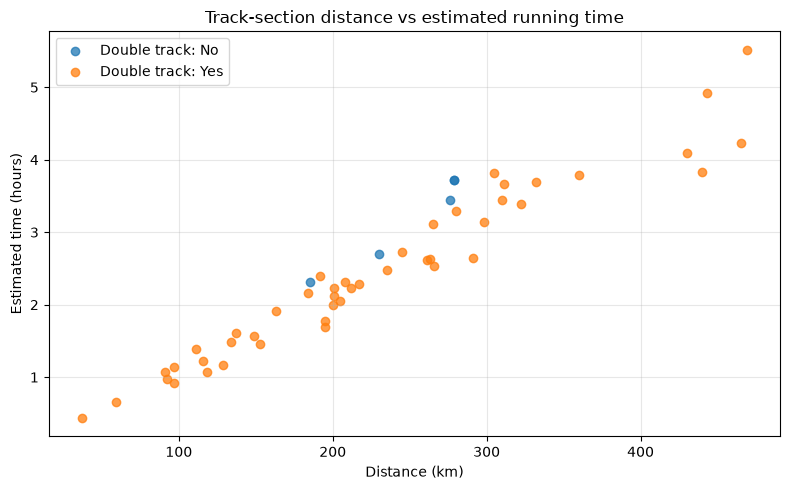

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
for track_type, group in df.groupby("Double_Track"):
    ax.scatter(group["Distance_km"], group["Travel_Time_h"], label=f"Double track: {track_type}", alpha=0.75)
ax.set(title="Track-section distance vs estimated running time", xlabel="Distance (km)", ylabel="Estimated time (hours)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "distance_vs_time.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 13 - Visualize the normal route and flood diversion

The diagram highlights the normal shortest-distance route and the **additional** track sections used by the flood diversion. Other edges are shown in grey; single-track sections are identified in the legend. The graph layout is for illustration and does not represent geographic coordinates or map scale.

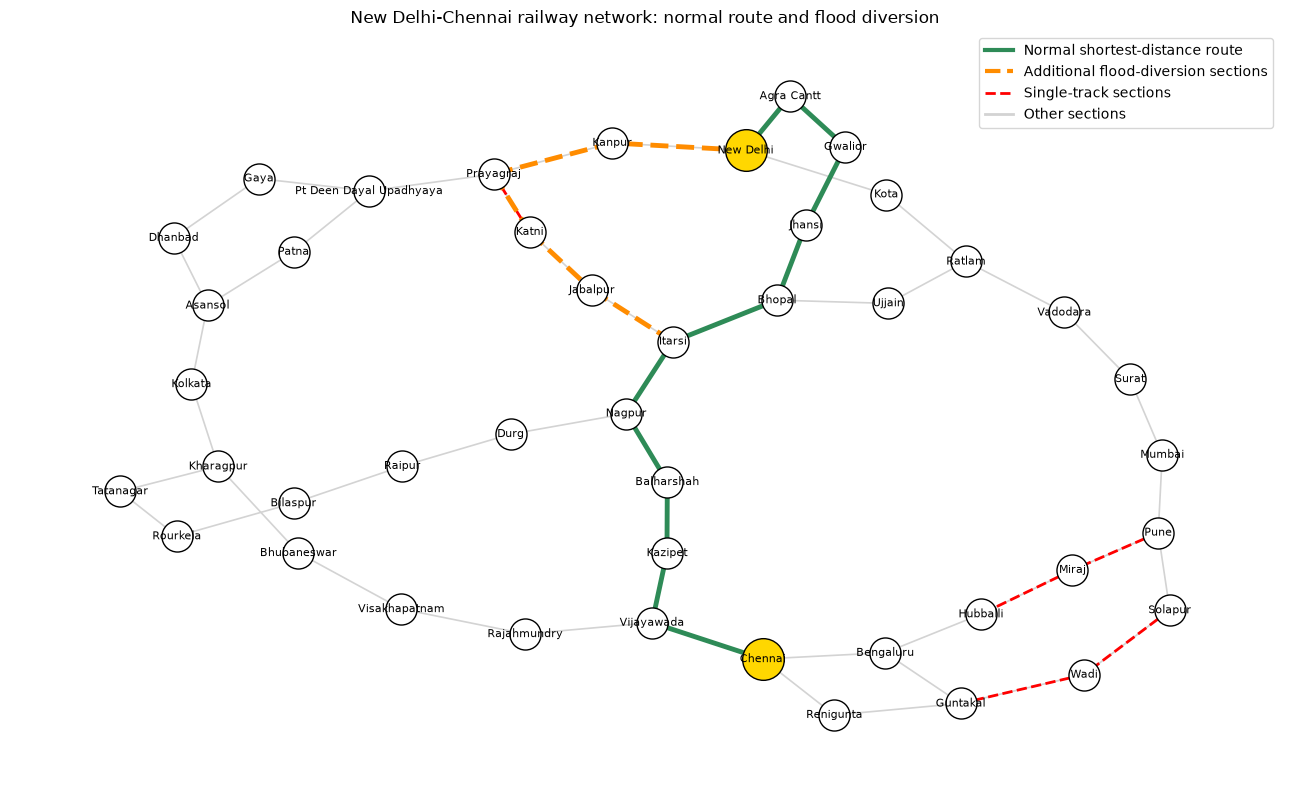

In [16]:
base_edges = list(zip(distance_route["path"], distance_route["path"][1:]))
flood_edges = list(zip(flood_distance_route["path"], flood_distance_route["path"][1:]))
base_edge_keys = {frozenset(edge) for edge in base_edges}
additional_flood_edges = [edge for edge in flood_edges if frozenset(edge) not in base_edge_keys]
single_track_edges = [
    (row.Origin, row.Destination)
    for row in df.itertuples(index=False)
    if row.Double_Track == "No"
]

position = nx.kamada_kawai_layout(G)
fig, ax = plt.subplots(figsize=(13, 8))
nx.draw_networkx_edges(G, position, edge_color="lightgrey", width=1.2, ax=ax)
nx.draw_networkx_edges(G, position, edgelist=single_track_edges, edge_color="red", style="dashed", width=2, ax=ax)
nx.draw_networkx_edges(G, position, edgelist=base_edges, edge_color="seagreen", width=3.5, ax=ax)
if additional_flood_edges:
    nx.draw_networkx_edges(G, position, edgelist=additional_flood_edges, edge_color="darkorange", style="dashed", width=3.5, ax=ax)
nx.draw_networkx_nodes(G, position, node_color="white", edgecolors="black", node_size=500, ax=ax)
nx.draw_networkx_nodes(G, position, nodelist=[SOURCE, DESTINATION], node_color="gold", edgecolors="black", node_size=900, ax=ax)
nx.draw_networkx_labels(G, position, font_size=8, ax=ax)

legend_items = [
    plt.Line2D([0], [0], color="seagreen", lw=3, label="Normal shortest-distance route"),
    plt.Line2D([0], [0], color="darkorange", lw=3, linestyle="--", label="Additional flood-diversion sections"),
    plt.Line2D([0], [0], color="red", lw=2, linestyle="--", label="Single-track sections"),
    plt.Line2D([0], [0], color="lightgrey", lw=2, label="Other sections"),
]
ax.legend(handles=legend_items, loc="best")
ax.set_title("New Delhi-Chennai railway network: normal route and flood diversion")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "normal_vs_flood_diversion.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 14 - Summarize findings and recommendation

The output below collects the route values computed by earlier cells. Use it together with the route diagram and closure-sensitivity table to explain the result. In this scenario, Katni-Prayagraj is a reasonable candidate for further capacity review because the diversion uses this single-track section. The graph does not quantify freight demand, construction cost, or alternative investments, so the finding is a scenario-based recommendation rather than a definitive infrastructure ranking.

In [17]:
print(f"Network: {G.number_of_nodes()} junctions and {G.number_of_edges()} track sections")
print(f"Normal route: {distance_route['distance_km']:.0f} km; {distance_route['time_h']:.2f} h estimated section running time")
print(f"Flood diversion: {flood_distance_route['distance_km']:.0f} km; {flood_distance_route['time_h']:.2f} h estimated section running time")
print(f"Flood impact: +{extra_distance:.0f} km; +{extra_time:.2f} h")
print(f"Single-track sections on flood diversion: {flood_distance_route['single_track_sections'] or 'None'}")
print("\nInterpretation: review the single-track Katni-Prayagraj link as a capacity risk on this diversion.")
print("This conclusion is limited to the supplied network and closure scenario.")
print(f"\nGenerated tables and figures are in: {OUTPUT_DIR.resolve()}")

Network: 44 junctions and 51 track sections
Normal route: 2181 km; 21.61 h estimated section running time
Flood diversion: 2635 km; 27.14 h estimated section running time
Flood impact: +454 km; +5.54 h
Single-track sections on flood diversion: ['Prayagraj - Katni']

Interpretation: review the single-track Katni-Prayagraj link as a capacity risk on this diversion.
This conclusion is limited to the supplied network and closure scenario.

Generated tables and figures are in: C:\Users\Nihar\.copilot\repos\copilot-worktrees\2026-28-MSc-DS-python\nihargowda21-oss-sturdy-adventure\indian-railways-freight-analysis\outputs
